# Descarga de datos para entrenar el CLASIFICADOR v3

Para entrenar `cnn_damage_classification_training3` en una computadora que no tiene las imagenes.
Se corre **una sola vez**, antes del entrenamiento.

Requisitos: AWS CLI instalado y configurado (`aws configure`) con acceso de lectura al bucket.

Deja en `notebooks/data_clasificacion/` (un nivel arriba de esta carpeta) las imagenes, las etiquetas y
`dataset_final.csv`. La carpeta esta en `.gitignore`. Nada de lo que hace este notebook modifica el bucket.

In [1]:
# Celda 1: configuracion

import os
import subprocess

BUCKET = "s3://humanoid-damage-cnn-834257582282-us-east-1-an/processed"
DATA_DETECCION = "../data"  # los datos quedan en notebooks/, fuera de parte3

Imagenes: 53748 | Labels: 53722
Total de clases en el dataset original: 64

  4456  Concrete spalling
  7649  Corrosion
   505  Crack
   187  Debris
   208  Detachment crack
  2499  Diagonal crack
   352  Flexural/rocking crack
    14  Large displacement
    67  Leaching
   272  Non structural damage
    25  Out-of-plane mechanism
   108  Partial/full collapse
    33  Rebar deformation/buckling
   918  Shear crack
  1261  -1-Earthquake-Induced Cracks And Collapses
   588  -2-Blistering
  2059  -3-Alveolization
   916  -4-Vegetation-Advanced Stage
   553  -5-Detachment
  1016  -6-Pitting
  2291  -7- Swelling
  1160  -8-Flaking
  2810  -9-Exfoliation
  1022  10-Vandalism
   853  11-Crumbling
  1003  12-Corrosion-Local Widespread
  2296  13-Delamination-Localized Spread
   594  14-Encrustation-Localized Spread
   611  0
  1184  1
  1667  crack
   128  damp
     4  dampness
  1003  mold
   158  peeling_paint
   111  stain
   716  stairstep_crack
   135  water_seepage
   100  Efflorescence


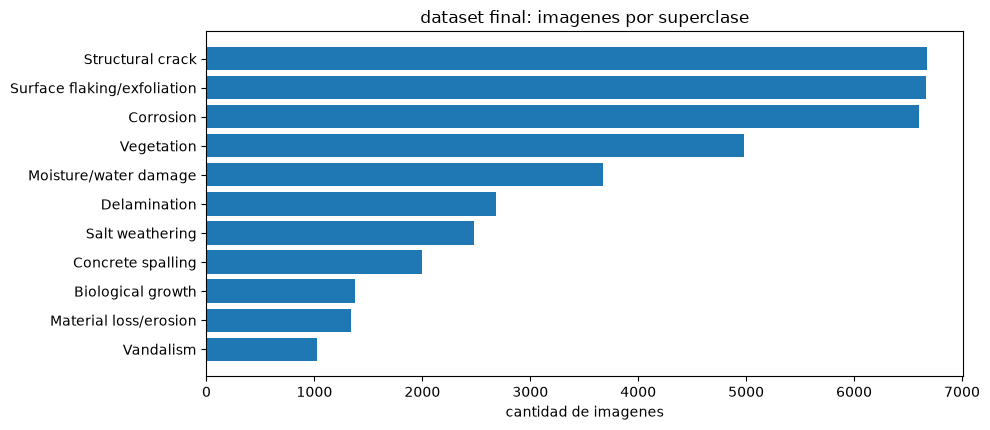

In [2]:
# Celda 2: imagenes de clasificacion y dataset_final.csv
# Corre el notebook que ya arma el dataset de clasificacion: baja las
# imagenes y etiquetas de S3, aplica los 11 grupos finales, limpia
# duplicados y archivos rotos, y guarda data_clasificacion/dataset_final.csv
# y grupos_final.json.
# Se corre desde notebooks/ porque ese notebook usa rutas relativas a esa carpeta.

os.chdir("..")
try:
    %run cnn_damage_classification_build_dataset.ipynb
finally:
    os.chdir("parte3")

In [3]:
# Celda 3: control final

listo = os.path.exists("../data_clasificacion/dataset_final.csv") and os.path.exists("../data_clasificacion/grupos_final.json")
print("Todo listo para entrenar el clasificador v3" if listo else "Falta algo: revisar la celda anterior")

Todo listo para entrenar el clasificador v3
